# <div align="center"><span style="color:red">Deep learning's final project</span></div>

# Subject : A deep learning aproach for brain tumor detection using magnetic resonance imaging 

----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### importing the necessary libararies : 

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, random_split, Subset
import nibabel as nib
import os
import pandas as pd
import random

### checking if there is a GPU available : 

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


### Loading the dataset :

In [35]:
path_dataset = "./BraTS dataset/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"

### in order to get some information about the dataset, we load the csv files in the directory : 

In [36]:
name_csv_path = os.path.join(path_dataset, "name_mapping.csv")
pd.read_csv(name_csv_path)

,Grade,BraTS_2017_subject_ID,BraTS_2018_subject_ID,TCGA_TCIA_subject_ID,BraTS_2019_subject_ID,BraTS_2020_subject_ID
0,HGG,Brats17_CBICA_AAB_1,Brats18_CBICA_AAB_1,NaN,BraTS19_CBICA_AAB_1,BraTS20_Training_001
1,HGG,Brats17_CBICA_AAG_1,Brats18_CBICA_AAG_1,NaN,BraTS19_CBICA_AAG_1,BraTS20_Training_002
2,HGG,Brats17_CBICA_AAL_1,Brats18_CBICA_AAL_1,NaN,BraTS19_CBICA_AAL_1,BraTS20_Training_003
3,HGG,Brats17_CBICA_AAP_1,Brats18_CBICA_AAP_1,NaN,BraTS19_CBICA_AAP_1,BraTS20_Training_004
4,HGG,Brats17_CBICA_ABB_1,Brats18_CBICA_ABB_1,NaN,BraTS19_CBICA_ABB_1,BraTS20_Training_005
...,...,...,...,...,...,...
364,HGG,NaN,NaN,NaN,NaN,BraTS20_Training_365
365,HGG,NaN,NaN,NaN,NaN,BraTS20_Training_366
366,HGG,NaN,NaN,NaN,NaN,BraTS20_Training_367
367,HGG,NaN,NaN,NaN,NaN,BraTS20_Training_368


In [37]:
survival_csv_path = os.path.join(path_dataset,"survival_info.csv")
pd.read_csv(survival_csv_path)

,Brats20ID,Age,Survival_days,Extent_of_Resection
0,BraTS20_Training_001,60.463,289,GTR
1,BraTS20_Training_002,52.263,616,GTR
2,BraTS20_Training_003,54.301,464,GTR
3,BraTS20_Training_004,39.068,788,GTR
4,BraTS20_Training_005,68.493,465,GTR
...,...,...,...,...
231,BraTS20_Training_363,57.000,62,GTR
232,BraTS20_Training_366,72.000,633,GTR
233,BraTS20_Training_367,60.000,437,STR
234,BraTS20_Training_368,49.000,442,GTR


Using the information we recieved through the csv files and looking at the dataset's folder, we know that there are 369 samples in the training dataset.

In [38]:
num_of_samples = 369

we can't use the test dataset for either training, validation or testing because they don't have label files.

we need to define a dataset class to load the dataset.     
dataset class needs to have some necessary functions :
1. first of all, we need to create the __init__ function. this is the place we define all of the objects. all the other functions use this to access the objects they need.

2. __len__ : this is the function that returns the number of samples in the dataset. 

3. **retrive_image :** this is the function that returns the 3D images by their index specified in the input. 

4. **retrive mask :** this is the function that returns the specified masks by their given index. 

5. **index_list :** there is a problem with this dataset. when we convert the 3D image into 2D slices, we create some empty slices. the reason behind this, is that there are  
    some empty spaces in the brain and the MRI images, show these with zero value. these slices can mess with the training and make a lot of noise. so we need to delete this slices or avoid considering them. the next problem we face with this approach is, first we don't know how many 2D samples we would have eventually. the second problem is that we won't know which case each index blongs to so we wouldn't be able to load the samples one by one. this function creates a list of the cases and their indexes for us. using this function we would know exactly where to look for each index and also we can calculate the total number of samples. 

6. **extract_slices :** this function gets the index in the input. it uses the total_index list to find out where to look for the image. then it loads the 3D image and its mask 
    using the retrive_image and retrive_mask functions. then it extracts the specified slice we want. after that it findes the image's label using the given mask and returns the 
    2D image and its lablel. 

7. __getitem__ : this is the function we use to return the images and labels one by one. this function gets the specified image and its label usinge the extract_slices function
    and converts their structure to the acceptable structure of pytorch. it then checks if there is a trasform specified in the class input and executes it on the image. and at last, it returns the image and its label at the output. 

In [39]:
class BraTSDataset(Dataset):
    def __init__(self, root_dir, num_of_samples ,transform=None):
        self.root_dir = root_dir
        self.num_of_samples = num_of_samples
        self.transform = transform
        self.total_index = self.index_list()
    
    def __len__(self):
        return len(self.total_index)
    
    def __getitem__(self, idx):
        image, label = self.extract_slices(idx)

        image = torch.from_numpy(image).float() # pytorch expects tensors but get_fdata function returns np.arrays
        label = torch.tensor(label).long() # crossentropyloss expects tensors with long dtype 
        image = image.unsqueeze(0) # at this point, images are 2 dimentional slices but CNN expects 3 dimentional images.
        # it doesn't matter if our images are grayscale, they still need to contain number of channels too.

        if self.transform is not None:
            image = self.transform(image)

        return image, label

    def retrive_image(self, idx):
        image_name = f"BraTS20_Training_{idx+1:03d}"
        image_path = os.path.join(self.root_dir, image_name , f"{image_name}_flair.nii")
        image = nib.load(image_path)
        image = image.get_fdata(dtype=np.float32)
        return image
    
    def retrive_mask(self, idx):
        mask_name = f"BraTS20_Training_{idx+1:03d}"
        mask_path = os.path.join(self.root_dir, mask_name, f"{mask_name}_seg.nii")
        mask = nib.load(mask_path)
        mask = mask.get_fdata(dtype=np.float32)
        return mask
    
    def extract_slices(self, idx):
        case, index = self.total_index[idx]
        threeD_image = self.retrive_image(case)
        mask = self.retrive_mask(case)

        image = threeD_image[:, :, index]
        mask_slice = mask[:, :, index]

        label = 1 if np.any(mask_slice > 0) else 0
        
        return image, label
        
    def index_list(self):
        total_index = []
        for case in range(self.num_of_samples):
            try:
                threeD_image = self.retrive_image(case)
                mask = self.retrive_mask(case)
                index = []

                for idx in range(threeD_image.shape[2]):
                    img_slice = threeD_image[:, :, idx]

                    if img_slice.max() == 0:
                        continue

                    index.append([case, idx])

                total_index += index
            except Exception as e:
                print(f"an error accourd during image {case + 1}'s loading :\n{e}")
        return total_index

In [40]:
dataset = BraTSDataset(path_dataset, num_of_samples)

an error accourd during image 355's loading :
No such file or no access: 'BraTS dataset/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_355/BraTS20_Training_355_seg.nii'


In [41]:
print(f"number of samples in the dataset : {len(dataset)}")

image, label = dataset[1000]
print(f"\nshape of the image : {image.shape} \nimage's label : {label}")

number of samples in the dataset : 50706

shape of the image : torch.Size([1, 240, 240]) 
image's label : 1


defining a class for Normalizing by slice : 

In [42]:
class Normalizer():
    def __call__(self, x):
        mean = x.mean()
        std = x.std()
        return (x - mean) / (std + 1e-6)

In [43]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    Normalizer()
])

val_transform = Normalizer()

as mentioned before, we can't use the test dataset for either training, validation or testing. so we need to split our dataset into three smaller datasets. 

there is something important we need to consider when spliting the dataset, as you know we have converted the 3D images into 2D slices. so it wouldn't be very thoughtfull to
    shuffle the samples by their indexes. it's better to shuffle them by their cases. 

In [44]:
def split_dataset(dataset, val_fraction=0.15, test_fraction=0.15, seed=42):
    random.seed(seed)
    val_size = int(num_of_samples * val_fraction)
    test_size = int(num_of_samples * test_fraction)

    list_of_samples = list(range(num_of_samples))
    random.shuffle(list_of_samples)
    val_cases = set(list_of_samples[:val_size])
    test_cases = set(list_of_samples[val_size : test_size + val_size])
    train_cases = set(list_of_samples[test_size + val_size: ])
    
    def allowed_slices(allowed_cases):
        allowed_idx = []
        for i, (case, _) in enumerate(dataset.total_index):
            if case in allowed_cases:
                allowed_idx.append(i)
        return allowed_idx
    
    val_idx = allowed_slices(val_cases)
    test_idx = allowed_slices(test_cases)
    train_idx = allowed_slices(train_cases)

    train_subset = Subset(dataset, train_idx)
    val_subset = Subset(dataset, val_idx)
    test_subset = Subset(dataset, test_idx)

    return train_subset, val_subset, test_subset

In [45]:
train_dataset, val_dataset, test_dataset = split_dataset(dataset)

In [46]:
print(f"Length of total dataset :     {len(dataset)}")
print(f"Length of training dataset:   {len(train_dataset)}")
print(f"Length of validation dataset: {len(val_dataset)}")
print(f"Length of test dataset:       {len(test_dataset)}")

Length of total dataset :     50706
Length of training dataset:   35504
Length of validation dataset: 7586
Length of test dataset:       7616


next step is executing a specific transform on each subset, we define another class to do the job :

In [47]:
class SubsetWithTransform(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

In [48]:
train_dataset = SubsetWithTransform(train_dataset, transform=train_transform)
val_dataset = SubsetWithTransform(val_dataset, transform=val_transform)
test_dataset = SubsetWithTransform(test_dataset, transform=val_transform)

In [49]:
print(train_dataset.transform, "\n")
print(val_dataset.transform, "\n")
print(test_dataset.transform)

Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
) 




we define a dataloader for each of the datasets. validation and test datasets don't need shuffling. 

In [50]:
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## defining the CNN : 
first we define a convblock class to avoid writing the same layers several times and keep the code cleaner and easier to debug.

In [51]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential( 
        nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
        )

    def forward(self, x):
        x = self.block(x)
        return x

now we can design the CNN architecture using the convblock we defined in the cell above.

we use the same architecture the paper has used. 

we also used the same parameters as the paper.

In [52]:
class ClassCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.block1 = nn.Sequential(
            ConvBlock(1, 16),
            ConvBlock(16, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 64),
            ConvBlock(64, 64)
        )

        self.flatten = nn.Flatten()

        self.block2 = nn.Sequential(
            nn.Linear(64 * 7 * 7, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.flatten(x)
        x = self.block2(x)
        return x

In [53]:
loss_function = nn.CrossEntropyLoss()

after designing the CNN's architucture, it is time to define a function for training the model. 

we define some lists to store the values of loss and accuracy for evaluating the procedure of training and being able to plot them after training. we return the values with the trianed model. 

In [54]:
def training_loop(model, train_loader, val_loader, loss_function, optimizer, num_epochs, device):
    model.to(device)
    train_loss = []
    val_loss = []
    train_accuracy = []
    val_accuracy = []

    print("--- Training Started ---")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = len(train_loader.dataset)
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * labels.size(0)

            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
        
        train_loss.append(running_loss / total)
        train_accuracy.append(100 * correct / total)

        model.eval()
        running_loss = 0.0
        correct = 0
        total = len(val_loader.dataset)

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = loss_function(outputs, labels)

                running_loss += loss.item() * labels.size(0)

                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()

            val_loss.append(running_loss / total)
            val_accuracy.append(100 * correct / total)

            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss[epoch]:.4f}, Val Loss: {val_loss[epoch]:.4f}, train Accuracy: {train_accuracy[epoch]:.2f}%, Val Accuracy: {val_accuracy[epoch]:.2f}%")

    print("--- Finished Training ---")

    metrics = [train_loss, val_loss, train_accuracy, val_accuracy]

    return model, metrics

for evaluating the model's performance on the test dataset, we don't need to calculate any gradient, so we use "model.eval()" and "with torch.no_grad()" to speed up the procedure. 

we also use precision, recall and f1 score as the main accuracy metrics. so we need to define a function for calculating these parameters before defining the main loop. 

In [55]:
def test(model, test_loader, loss_function, device):
    model.to(device)
    tp = 0
    tn = 0
    fp = 0
    fn = 0
    running_loss = 0

    def f1(tp, tn, fp, fn):
        precision = tp / (tp + fp + 1e-8)
        recall = tp / (tp + fn + 1e-8)
        f1 = 2 * precision * recall / (precision + recall + 1e-8)
        return precision, recall, f1

    model.eval()
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_function(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            _, predicted = outputs.max(1)
            for i in range(len(predicted)):
                if predicted[i].item() == labels[i].item():
                    if predicted[i].item() == 0:
                        tn += 1
                    else:
                        tp += 1
                else:
                    if predicted[i].item() == 0:
                        fn += 1
                    else:
                        fp += 1

        total = tn + tp + fn + fp
        loss = (running_loss / total)
        accuracy = ((tp + tn) / total)
        precision, recall, f1accuracy = f1(tp, tn, fp, fn)

        return loss, accuracy, precision, recall, f1accuracy

In [56]:
model = ClassCNN()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0005)
num_epochs = 40
print(model)

ClassCNN(
  (block1): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (3): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_m

In [57]:
trained_model, training_metrics = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=num_epochs,
    device=device
)

--- Training Started ---
Epoch [1/40], Train Loss: 0.3630, Val Loss: 0.2533, train Accuracy: 83.22%, Val Accuracy: 88.81%
Epoch [2/40], Train Loss: 0.2424, Val Loss: 0.2168, train Accuracy: 90.17%, Val Accuracy: 91.00%
Epoch [3/40], Train Loss: 0.2238, Val Loss: 0.1987, train Accuracy: 91.09%, Val Accuracy: 92.05%
Epoch [4/40], Train Loss: 0.2130, Val Loss: 0.2135, train Accuracy: 91.55%, Val Accuracy: 91.25%
Epoch [5/40], Train Loss: 0.2073, Val Loss: 0.2007, train Accuracy: 91.78%, Val Accuracy: 91.79%
Epoch [6/40], Train Loss: 0.2029, Val Loss: 0.2058, train Accuracy: 91.90%, Val Accuracy: 91.84%
Epoch [7/40], Train Loss: 0.2009, Val Loss: 0.1965, train Accuracy: 92.11%, Val Accuracy: 92.16%
Epoch [8/40], Train Loss: 0.1963, Val Loss: 0.2117, train Accuracy: 92.21%, Val Accuracy: 91.44%
Epoch [9/40], Train Loss: 0.1986, Val Loss: 0.2266, train Accuracy: 92.15%, Val Accuracy: 90.86%
Epoch [10/40], Train Loss: 0.1930, Val Loss: 0.2221, train Accuracy: 92.39%, Val Accuracy: 90.97%
Epoc

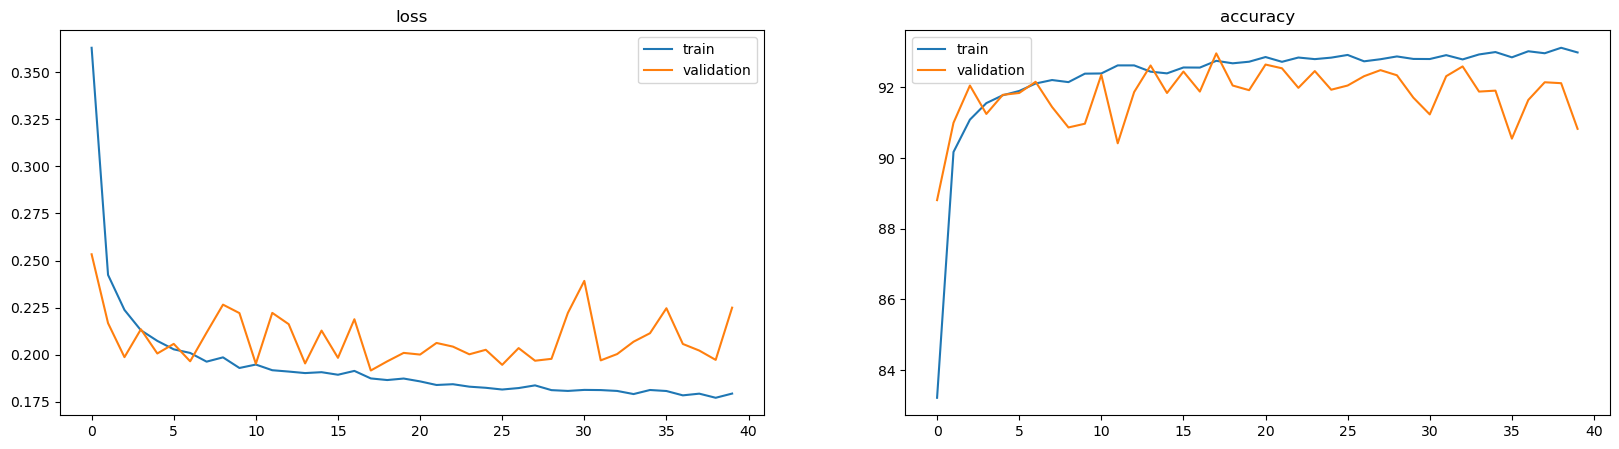

In [58]:
plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.plot(range(num_epochs), training_metrics[0], label="train")
plt.plot(range(num_epochs), training_metrics[1], label="validation")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(range(num_epochs), training_metrics[2], label="train")
plt.plot(range(num_epochs), training_metrics[3], label="validation")
plt.title("accuracy")
plt.legend()
plt.show()

Test results : 

loss: 0.2340295843266686 
accuracy: 90.04726890756302% 
precision: 93.35880105761576% 
recall: 85.65651118876879% 
F1 accuracy: 89.34195675601745%


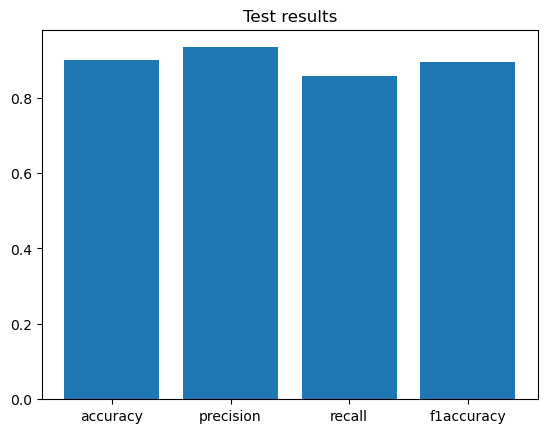

In [59]:
loss, accuracy, precision, recall, f1accuracy = test(model=trained_model, test_loader=test_loader, loss_function=loss_function, device=device)

print(f"Test results : \n")
print(f"loss: {loss} \naccuracy: {accuracy * 100}% \nprecision: {precision * 100}% \nrecall: {recall * 100}% \nF1 accuracy: {f1accuracy * 100}%")

x = ['accuracy', 'precision', 'recall', 'f1accuracy']
y = [accuracy, precision, recall, f1accuracy]
plt.bar(x, y)
plt.title("Test results")
plt.show()